In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from collections import defaultdict
from pathlib import Path
sys.path.append('/home/563/sc1326/repos/cdrmip_extremes')
from cdrmip_extremes.configs import data_dir, proc_dir
from cdrmip_extremes.sat import find_crossing_years, find_matching_gwls
from cdrmip_extremes import processing, utils, ext_freq, utils_scenariomip
from cdrmip_extremes.CMIP6_file_search import find_CMIP_files, search_and_load, search_and_load_parent, concatenate_branches

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [17]:
data = {}
for var in ['sftlf','areacella']:
    df = find_CMIP_files(
        experiment_id='ssp534-over',
        table_id = 'fx',
        variable_id=var,
        source_id='ACCESS-ESM1-5',
        member_id='r1i1p1f2'
    )
    path = df['path'][0]
    ds = xr.open_mfdataset(path,drop_variables=['lat_bnds','lon_bnds'])
    # regrid to common
    data[var] = processing.regrid_to_common(ds)

Building regridder for grid (145,) x (192,)


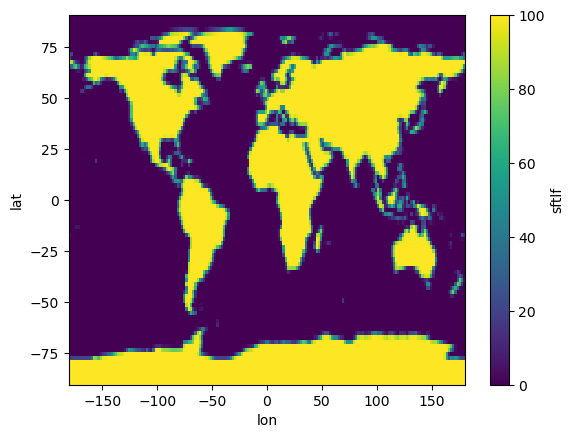

In [18]:
ds = data['sftlf'].sftlf
ds.plot()

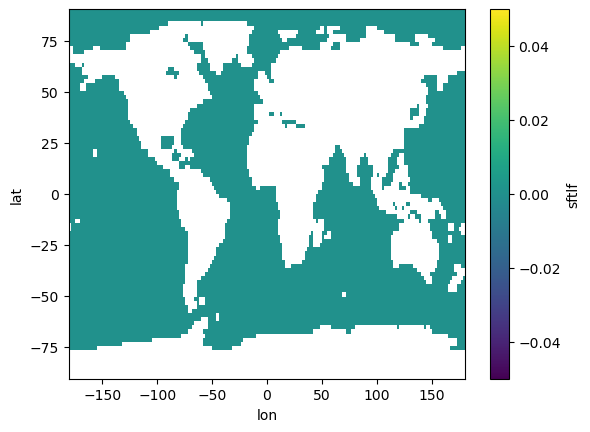

In [22]:
ds.where(ds<=0).plot()